# e34: transferability suite on Norway (2026-10-16)

Train on a coarse sample of the Norway DEM, test on the stride-4 grid of the same terrain
(`full_test-004.npz`: 250k nodes, 10 sources × 250k targets). Design and results: `docs/2026-10-e34-transfer-suite.md`.

| Item | Value |
| --- | --- |
| Models | MLP on xyz, TAGConv K=3, SparseGT k=2 (RPEARL data mode); siamese L1 head |
| Schemes | grid, uniform, Poisson-disk, slope-adaptive, quadtree |
| Training strides | 32, 24, 16, 12, 8, 4 (3,969 to 250,000 nodes) |
| Recipe | e32: batch 8192, AdamW wd 0.1, warmup 300, constant lr; SparseGT 200 epochs, others 100 |

Sections:
1. Transferability curves, one panel per scheme.
2. Three sample paths per model, for models trained on the smallest grid (stride 32) and the largest (stride 4).
3. Error heatmaps on the test terrain for one hard source.

Section 2 and 3 run on the test terrain. A model predicts distances only. I draw its path by greedy descent:
from node $i$, step to the unvisited neighbour $j$ that minimises $w_{ij} + \hat d(j, t)$.
The path is the route the model's distance field implies, not a model output.

Cached arrays go to `$E34_RUNS/analysis/cache`, so a rerun without a GPU needs only that folder.

In [1]:
import glob, json, os, re
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.csgraph import dijkstra

RUNS = Path(os.environ.get('E34_RUNS', '~/runs/e34')).expanduser()
DATA = Path(os.environ.get('E34_DATA', '~/data/spnn/e31')).expanduser()
TEST = Path(os.environ.get('E34_TEST', '~/data/spnn/full_test-004.npz')).expanduser()
REPO = Path(os.environ.get('SPNN_REPO', '..')).resolve()
CACHE = RUNS / 'analysis' / 'cache'
FIGS = RUNS / 'analysis' / 'figures'
CACHE.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)

SCHEMES = ['grid', 'uniform', 'poisson-disk', 'slope-adaptive', 'quadtree']
SCHEME_TITLES = {'grid': 'Grid', 'uniform': 'Uniform', 'poisson-disk': 'Poisson-disk',
                 'slope-adaptive': 'Slope-adaptive', 'quadtree': 'Quadtree'}
STRIDES = [32, 24, 16, 12, 8, 4]
MODELS = ['mlp', 'tagconv', 'sgt2']
MODEL_NAMES = {'mlp': 'MLP', 'tagconv': 'TAGConv', 'sgt2': 'SparseGT'}

# Colours and markers from notebooks/PLOTTING_STYLE.md: TAGConv takes the GNN baseline style,
# SparseGT the Sparse GT colour; MLP takes the first extra colour.
PALETTE = {'mlp': '#e07a5f', 'tagconv': '#7f8c8d', 'sgt2': '#81b29a'}
MARKERS = {'mlp': 's', 'tagconv': 'o', 'sgt2': 'v'}
def line_attrs(model, base_lw=1.2, base_ms=3.5):
    if model == 'tagconv':
        return dict(lw=base_lw * 0.55, ms=base_ms * 0.78, alpha=0.78, ls='--', zorder=2)
    if model == 'sgt2':
        return dict(lw=base_lw * 1.05, ms=base_ms * 1.05, alpha=1.0, ls='-', zorder=5)
    return dict(lw=base_lw, ms=base_ms, alpha=0.95, ls='-', zorder=3)

RC = {'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none', 'axes.unicode_minus': False,
      'font.family': 'serif', 'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
      'mathtext.fontset': 'stix', 'font.size': 9, 'axes.labelsize': 9, 'axes.titlesize': 9,
      'axes.titlepad': 4, 'axes.titlelocation': 'left', 'legend.fontsize': 8,
      'xtick.labelsize': 8, 'ytick.labelsize': 8, 'axes.linewidth': 0.7}
mpl.rcParams.update(RC)

def clean_axes(ax):
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color('#444')
    ax.tick_params(colors='#444')

# Reference numbers on the same test set (docs/2026-10-e31-sampling-transfer.md, section 6).
REFS = {'GAT+L1 (Chen stage 1, grid s8)': (0.52, ':'), 'octile+dz×c, no training': (1.12, '-.')}

## 1. Transferability curves

In [2]:
rows = []
for f in sorted(RUNS.glob('norway_*_s??_*.json')) + sorted((RUNS / 'seed1').glob('norway_*_s??_*.json')):
    m = re.match(r'norway_(.+)_s(\d\d)_(\w+)\.json', f.name)
    scheme, stride, model = m[1], int(m[2]), m[3]
    seed = 0
    if scheme.endswith('-seed1'):
        scheme, seed = scheme[:-len('-seed1')], 1
    final = json.load(open(f))['final']
    info = json.load(open(DATA / f'norway_{m[1]}_s{m[2]}.json'))
    rows.append(dict(scheme=scheme, stride=stride, model=model, seed=seed, n_nodes=info['n_nodes'],
                     test_nmae=100 * final['test_nmae'], test_acc2=100 * final['test_acc_2pct'],
                     train_nmae=100 * final['final_train_nmae']))
res = pd.DataFrame(rows)
print(f"{len(res[res.seed == 0])} of 90 suite runs, {len(res[res.seed == 1])} seed-1 runs")
res[res.seed == 0].pivot_table(index=['scheme', 'stride'], columns='model', values='test_nmae') \
    .reindex(columns=MODELS).loc[SCHEMES].round(2)

90 of 90 suite runs, 3 seed-1 runs


model                    mlp  tagconv   sgt2
scheme         stride                       
grid           4        0.71     0.83   0.62
               8        0.69     0.77   0.62
               12       0.69     0.79   0.60
               16       0.70     0.83   0.65
               24       0.75     0.97   0.70
               32       0.83     1.04   0.87
uniform        4        1.67     1.74   1.63
               8        1.69     1.73   1.62
               12       1.76     1.79   1.72
               16       1.76     1.75   1.66
               24       1.74     1.83   1.85
               32       1.81     2.11   2.02
poisson-disk   4        2.20     2.28   2.25
               8        2.24     2.41   2.38
               12       2.23     2.36   2.34
               16       2.39     2.38   2.38
               24       2.46     2.41   2.57
               32       2.52     2.47   2.54
slope-adaptive 4        1.71     1.69   1.62
               8        1.76     1.75   1.64
               12       1.81     1.80   1.71
               16       1.83     1.79   1.84
               24       1.98     2.08   2.47
               32       1.64     1.91   1.98
quadtree       4       19.98    19.96  19.90
               8       20.07    20.03  19.92
               12      20.19    19.99  19.99
               16      20.20    19.96  20.00
               24      19.84    19.81  19.79
               32      19.84    19.94  19.69

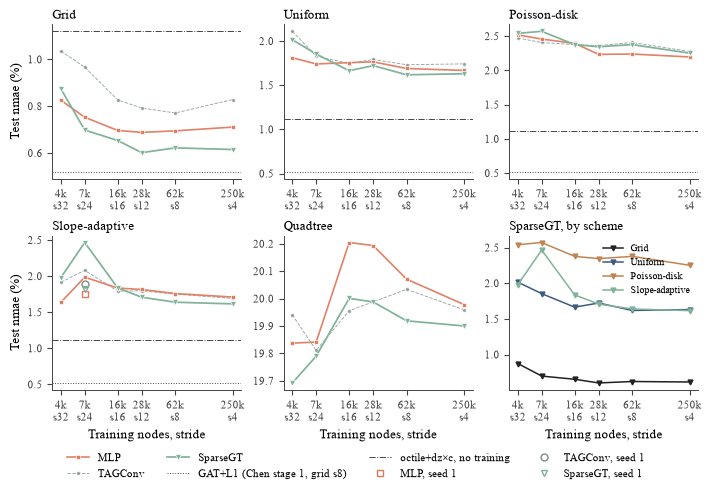

In [3]:
def plot_transfer(metric='test_nmae', ylabel='Test nmae (%)', refs=True, fname='e34_transfer_nmae'):
    fig, axes = plt.subplots(2, 3, figsize=(7.0, 4.4), constrained_layout=True)
    ticks = sorted(res[res.scheme == 'grid'].drop_duplicates('stride')[['n_nodes', 'stride']].values.tolist())
    for ax, scheme in zip(axes.ravel(), SCHEMES):
        sub = res[(res.scheme == scheme) & (res.seed == 0)]
        for model in MODELS:
            g = sub[sub.model == model].sort_values('n_nodes')
            ax.plot(g.n_nodes, g[metric], marker=MARKERS[model], color=PALETTE[model], label=MODEL_NAMES[model],
                    markeredgecolor='white', markeredgewidth=0.5, **line_attrs(model))
            s1 = res[(res.scheme == scheme) & (res.seed == 1) & (res.model == model)]
            if len(s1):
                ax.plot(s1.n_nodes, s1[metric], marker=MARKERS[model], ls='none', mfc='none',
                        color=PALETTE[model], ms=5, label=f'{MODEL_NAMES[model]}, seed 1')
        if refs and scheme != 'quadtree':
            for name, (val, ls) in REFS.items():
                ax.axhline(val if metric == 'test_nmae' else np.nan, color='#444', lw=0.7, ls=ls, label=name)
        ax.set_xscale('log')
        ax.set_xticks([n for n, _ in ticks], [f'{n/1000:.0f}k\ns{s}' for n, s in ticks])
        ax.minorticks_off()
        ax.set_title(SCHEME_TITLES[scheme])
        clean_axes(ax)
    # Last panel: SparseGT on every scheme except quadtree, to compare schemes on one axis.
    ax = axes.ravel()[-1]
    for scheme, c in zip(SCHEMES[:-1], ['#222', '#3d5a80', '#c08552', '#81b29a']):
        g = res[(res.scheme == scheme) & (res.model == 'sgt2') & (res.seed == 0)].sort_values('n_nodes')
        ax.plot(g.n_nodes, g[metric], marker='v', color=c, lw=1.1, ms=3.5, label=SCHEME_TITLES[scheme])
    ax.set_xscale('log'); ax.minorticks_off()
    ax.set_xticks([n for n, _ in ticks], [f'{n/1000:.0f}k\ns{s}' for n, s in ticks])
    ax.set_title('SparseGT, by scheme'); ax.legend(frameon=False, fontsize=7); clean_axes(ax)
    for ax in axes[1, :]:
        ax.set_xlabel('Training nodes, stride')
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    h, l = axes[0, 0].get_legend_handles_labels()
    h2, l2 = axes[1, 0].get_legend_handles_labels()   # slope-adaptive panel has the seed-1 markers
    seen = dict(zip(l, h)); seen.update({k: v for k, v in zip(l2, h2) if 'seed 1' in k})
    fig.legend(seen.values(), seen.keys(), loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.1))
    fig.savefig(FIGS / f'{fname}.pdf', bbox_inches='tight')
    plt.show()

plot_transfer()

Reading the curves:
- **Grid.** All three models improve from 4k to 28k training nodes and are flat after that. SparseGT at stride 12 (28k nodes) equals SparseGT trained on the full 250k-node test graph.
- **Irregular schemes.** The curves are flat at every density, also at 250k nodes. Training error is low (0.7–1.3%), so the models carry the metric of their training graph to the grid test graph (e31 section 7).
- **Seed 1.** The hollow markers are a second sampling seed of slope-adaptive stride 24. The seed spread (0.2–0.65 points) is as large as the model differences on the irregular schemes.

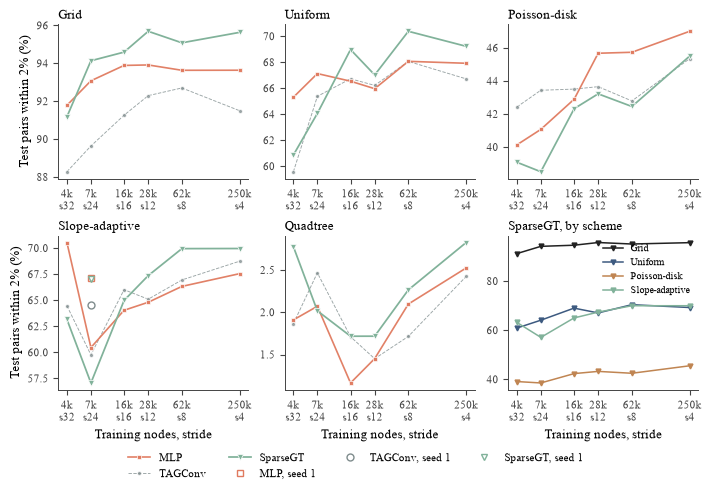

In [4]:
plot_transfer('test_acc2', 'Test pairs within 2% (%)', refs=False, fname='e34_transfer_acc2')

## 2. Sample paths: models trained on the smallest and the largest grid

Pairs: the detour ratio is the true length over the octile+dz length, the shortest path on a flat 8-neighbour grid
with the height difference added. A ratio of 1 means the route is the straight grid route; above 1 it bends around terrain.
Measuring against the 3D straight line instead picks grid artefacts (octile factor up to 1.08), not terrain.
For each test source I take the target 6–14 km away with the largest ratio, then the three sources with the largest such ratio.
The true path comes from Dijkstra on the test graph.

In [5]:
import sys, torch, yaml
sys.path.insert(0, str(REPO))
from spnn.models.factory import configure_embedding_module

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
test = np.load(TEST)
X = test['node_features']
N = len(X)
SIDE = int(round(np.sqrt(N)))                       # 500 x 500, x varies fastest
Z = X[:, 2].reshape(SIDE, SIDE)
EXTENT = [X[:, 0].min(), X[:, 0].max(), X[:, 1].min(), X[:, 1].max()]
ei, w = test['edge_index'], test['distances']
G = sp.csr_matrix((w, (ei[0], ei[1])), shape=(N, N))

srcs, tars, lengths = test['srcs'], test['tars'], test['lengths']
euclid = np.linalg.norm(X[srcs] - X[tars], axis=1)
dxy = np.abs(X[srcs, :2] - X[tars, :2])
octile = dxy.max(1) + (np.sqrt(2) - 1) * dxy.min(1)
octile_dz = np.sqrt(octile ** 2 + (X[srcs, 2] - X[tars, 2]) ** 2)
detour = np.where(octile_dz > 0, lengths / np.maximum(octile_dz, 1e-9), 1.0)
pairs = pd.DataFrame(dict(src=srcs, tar=tars, length=lengths, euclid=euclid, detour=detour))
cand = pairs[(pairs.length > 6) & (pairs.length < 14)]
best = cand.loc[cand.groupby('src').detour.idxmax()].sort_values('detour', ascending=False)
PATH_PAIRS = best.head(3).reset_index(drop=True)
PATH_PAIRS

,src,tar,length,euclid,detour
0,247792,185417,7.902588,7.075831,1.116842
1,137059,232559,8.449612,7.644498,1.105319
2,158393,228386,6.308701,5.612259,1.102679


In [6]:
MODEL_SPEC = {
    'mlp':     ('MLP',      'configs/e31-mlp.yml'),
    'tagconv': ('TAGConv',  'configs/e31-tagconv.yml'),
    'sgt2':    ('SparseGT', 'configs/e32-sparse-gt-k2.yml'),
}

def run_dir(scheme, stride, model):
    return RUNS / f'norway_{scheme}_s{stride:02d}_{model}'

def embeddings(scheme, stride, model):
    # Node embeddings of the test graph from a trained run; cached as float16.
    path = CACHE / f'emb_{scheme}_s{stride:02d}_{model}.npy'
    if path.exists():
        return np.load(path).astype(np.float32)
    layer_type, cfg_path = MODEL_SPEC[model]
    cfg = next(iter(yaml.safe_load(open(REPO / cfg_path)).values()))
    if layer_type == 'SparseGT':
        cfg['gnn'].setdefault('sparse_gt', {})['embedding_mode'] = 'data'
    net = configure_embedding_module(cfg['gnn'], layer_type, edge_dim=1, new=True)
    weights = next(run_dir(scheme, stride, model).glob('models/**/final_model.pt'))
    net.load_state_dict(torch.load(weights, map_location='cpu'))
    net = net.to(DEVICE).eval()
    x = torch.tensor(X, dtype=torch.float, device=DEVICE)
    with torch.no_grad():
        if layer_type == 'MLP':
            e = net(x)
        else:
            e = net(x, torch.tensor(ei, dtype=torch.long, device=DEVICE),
                    edge_attr=torch.tensor(w, dtype=torch.float, device=DEVICE).unsqueeze(-1))
    e = e.cpu().numpy()
    np.save(path, e.astype(np.float16))
    del net; torch.cuda.empty_cache() if DEVICE == 'cuda' else None
    return e

def true_path(s, t):
    dist, pred = dijkstra(G, indices=s, return_predecessors=True)
    path = [t]
    while path[-1] != s:
        path.append(pred[path[-1]])
    return path[::-1], dist[t]

def greedy_path(E, s, t, max_steps=20000):
    # Step to the unvisited neighbour j that minimises w_ij + d_hat(j, t), with d_hat the L1 embedding distance.
    h = np.abs(E - E[t]).sum(1)
    path, seen, i = [s], {s}, s
    while i != t and len(path) < max_steps:
        nb = G.indices[G.indptr[i]:G.indptr[i + 1]]
        wt = G.data[G.indptr[i]:G.indptr[i + 1]]
        ok = np.array([j not in seen for j in nb])
        if not ok.any():
            break                                     # dead end: report as unfinished
        nb, wt = nb[ok], wt[ok]
        i = int(nb[np.argmin(wt + h[nb])])
        path.append(i); seen.add(i)
    length = sum(G[a, b] for a, b in zip(path[:-1], path[1:]))
    return path, length, i == t, h[s]

PATH_STRIDES = [32, 4]
path_cache = CACHE / 'paths_grid_v2.json'
if path_cache.exists():
    PATHS = json.load(open(path_cache))
else:
    PATHS = {}
    for k, r in PATH_PAIRS.iterrows():
        s, t = int(r.src), int(r.tar)
        tp, tl = true_path(s, t)
        PATHS[f'{k}/true'] = dict(path=[int(v) for v in tp], length=float(tl))
    for stride in PATH_STRIDES:
        for model in MODELS:
            E = embeddings('grid', stride, model)
            for k, r in PATH_PAIRS.iterrows():
                p, L, done, dhat = greedy_path(E, int(r.src), int(r.tar))
                PATHS[f'{k}/{model}/s{stride}'] = dict(path=[int(v) for v in p], length=float(L),
                                                        reached=bool(done), pred=float(dhat))
    json.dump(PATHS, open(path_cache, 'w'))

tab = []
for k, r in PATH_PAIRS.iterrows():
    T = PATHS[f'{k}/true']['length']
    for stride in PATH_STRIDES:
        for model in MODELS:
            q = PATHS[f'{k}/{model}/s{stride}']
            tab.append(dict(pair=k, train=f'grid s{stride}', model=MODEL_NAMES[model], true_km=round(T, 3),
                            predicted_km=round(q['pred'], 3), pred_err_pct=round(100 * (q['pred'] - T) / T, 2),
                            greedy_km=round(q['length'], 3), greedy_excess_pct=round(100 * (q['length'] - T) / T, 2),
                            reached=q['reached']))
pd.DataFrame(tab)

,pair,train,model,true_km,predicted_km,pred_err_pct,greedy_km,greedy_excess_pct,reached
0,0,grid s32,MLP,7.903,7.376,-6.66,8.066,2.07,True
1,0,grid s32,TAGConv,7.903,7.493,-5.18,9.831,24.40,True
2,0,grid s32,SparseGT,7.903,7.361,-6.85,8.197,3.73,True
3,0,grid s4,MLP,7.903,7.587,-3.99,8.087,2.33,True
4,0,grid s4,TAGConv,7.903,7.613,-3.66,8.070,2.12,True
5,0,grid s4,SparseGT,7.903,7.601,-3.82,8.109,2.61,True
6,1,grid s32,MLP,8.450,8.169,-3.32,8.497,0.56,True
7,1,grid s32,TAGConv,8.450,8.220,-2.71,8.476,0.32,True
8,1,grid s32,SparseGT,8.450,8.229,-2.61,8.498,0.57,True
9,1,grid s4,MLP,8.450,8.272,-2.10,8.496,0.55,True


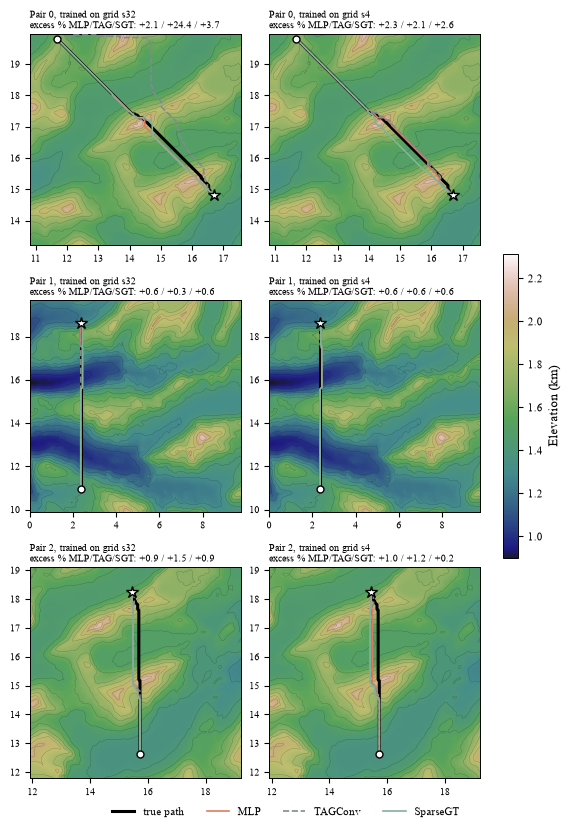

In [7]:
def plot_paths(fname='e34_paths_grid'):
    fig, axes = plt.subplots(len(PATH_PAIRS), len(PATH_STRIDES), figsize=(5.6, 8.0), constrained_layout=True)
    for k, r in PATH_PAIRS.iterrows():
        tp = np.array(PATHS[f'{k}/true']['path'])
        allpts = [tp] + [np.array(PATHS[f'{k}/{m}/s{s}']['path']) for m in MODELS for s in PATH_STRIDES]
        allpts = np.concatenate(allpts)
        x0, x1 = X[allpts, 0].min(), X[allpts, 0].max()
        y0, y1 = X[allpts, 1].min(), X[allpts, 1].max()
        half = 0.6 * max(x1 - x0, y1 - y0) + 0.3
        half = min(half, (EXTENT[1] - EXTENT[0]) / 2)
        cx = np.clip((x0 + x1) / 2, EXTENT[0] + half, EXTENT[1] - half)   # keep the window on the terrain
        cy = np.clip((y0 + y1) / 2, EXTENT[2] + half, EXTENT[3] - half)
        for c, stride in enumerate(PATH_STRIDES):
            ax = axes[k, c]
            im = ax.imshow(Z, origin='lower', extent=EXTENT, cmap='gist_earth', alpha=0.9)
            ax.contour(Z, levels=15, origin='lower', extent=EXTENT, colors='k', linewidths=0.2, alpha=0.4)
            ax.plot(X[tp, 0], X[tp, 1], color='k', lw=2.2, label='true path', zorder=4)
            for model in MODELS:
                q = PATHS[f'{k}/{model}/s{stride}']
                p = np.array(q['path'])
                ax.plot(X[p, 0], X[p, 1], color=PALETTE[model], lw=1.2,
                        ls='--' if model == 'tagconv' else '-', zorder=5,
                        label=f"{MODEL_NAMES[model]}")
            ax.plot(*X[int(r.src), :2], 'o', color='white', mec='k', ms=5, zorder=6)
            ax.plot(*X[int(r.tar), :2], '*', color='white', mec='k', ms=9, zorder=6)
            ax.set_xlim(cx - half, cx + half); ax.set_ylim(cy - half, cy + half)
            ax.set_aspect('equal')
            ex = ' / '.join(f"{100 * (PATHS[f'{k}/{m}/s{stride}']['length'] / PATHS[f'{k}/true']['length'] - 1):+.1f}"
                            for m in MODELS)
            ax.set_title(f"Pair {k}, trained on grid s{stride}\nexcess % MLP/TAG/SGT: {ex}", fontsize=7)
            ax.tick_params(labelsize=7)
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.03))
    fig.colorbar(im, ax=axes, shrink=0.4, label='Elevation (km)')
    fig.savefig(FIGS / f'{fname}.pdf', bbox_inches='tight')
    plt.show()

plot_paths()

## 3. Error heatmaps for one hard source

The source is the test source whose paths bend most: the largest mean detour ratio (true / octile+dz, as in section 2)
over targets more than 2 km away.
Each panel shows the signed relative error $(\hat d - d)/d$ of a model for every node of the test terrain as target.
Red means the model overestimates the distance, blue that it underestimates.

In [8]:
far = pairs[pairs.euclid > 2]
src_detour = far.groupby('src').detour.mean().sort_values(ascending=False)
HARD_SRC = int(src_detour.index[0])
print('mean detour per source (targets > 2 km):'); print(src_detour.round(4).to_string())
print('hard source', HARD_SRC, 'at', X[HARD_SRC].round(2))

def rel_error_map(scheme, stride, model, src=HARD_SRC):
    path = CACHE / f'heat_{scheme}_s{stride:02d}_{model}_src{src}.npy'
    if path.exists():
        return np.load(path)
    f = next(run_dir(scheme, stride, model).glob('models/**/preds.csv.gz'))
    df = pd.read_csv(f, usecols=['srcs', 'tars', 'preds', 'lengths'])
    df = df[df.srcs.astype(int) == src]
    m = np.full(N, np.nan, dtype=np.float32)
    ok = df.lengths.values > 0
    m[df.tars.values[ok].astype(int)] = (df.preds.values[ok] - df.lengths.values[ok]) / df.lengths.values[ok]
    np.save(path, m)
    return m

true_d = dijkstra(G, indices=HARD_SRC)

mean detour per source (targets > 2 km):
src
239655    1.0356
174202    1.0338
33603     1.0250
210330    1.0249
247792    1.0248
9063      1.0227
42546     1.0214
27034     1.0212
137059    1.0211
158393    1.0196
hard source 239655 at [ 6.2  19.17  1.83]


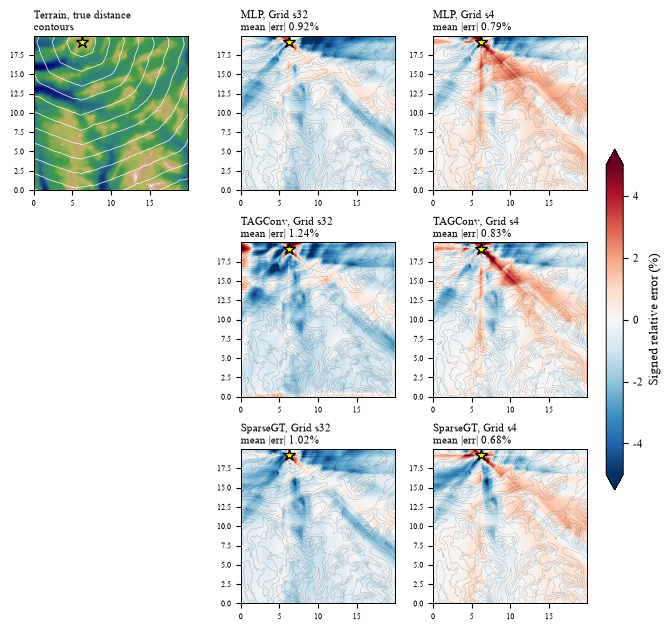

In [9]:
def plot_heatmaps(scheme='grid', strides=(32, 4), vmax=5.0, fname=None):
    fig, axes = plt.subplots(len(MODELS), len(strides) + 1, figsize=(2.0 * (len(strides) + 1) + 0.6, 6.2),
                             constrained_layout=True)
    for r, model in enumerate(MODELS):
        ax = axes[r, 0]
        if r == 0:
            ax.imshow(Z, origin='lower', extent=EXTENT, cmap='gist_earth')
            ax.contour(true_d.reshape(SIDE, SIDE), levels=12, origin='lower', extent=EXTENT, colors='w', linewidths=0.5)
            ax.set_title('Terrain, true distance\ncontours', fontsize=8)
        else:
            ax.axis('off')
        for c, stride in enumerate(strides, start=1):
            ax = axes[r, c]
            m = 100 * rel_error_map(scheme, stride, model)
            im = ax.imshow(m.reshape(SIDE, SIDE), origin='lower', extent=EXTENT, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
            ax.contour(Z, levels=10, origin='lower', extent=EXTENT, colors='k', linewidths=0.2, alpha=0.4)
            ax.set_title(f'{MODEL_NAMES[model]}, {SCHEME_TITLES[scheme]} s{stride}\n'
                         f'mean |err| {np.nanmean(np.abs(m)):.2f}%', fontsize=8)
        for c in range(len(strides) + 1):
            if r > 0 and c == 0:
                continue
            axes[r, c].plot(*X[HARD_SRC, :2], '*', color='yellow', mec='k', ms=9)
            axes[r, c].tick_params(labelsize=6)
    fig.colorbar(im, ax=axes[:, 1:], shrink=0.6, label='Signed relative error (%)', extend='both')
    if fname:
        fig.savefig(FIGS / f'{fname}.pdf', bbox_inches='tight')
    plt.show()

plot_heatmaps('grid', fname='e34_heatmap_grid')

The same source for models trained on the uniform scheme. This shows where the isotropic kNN metric of the training
graph departs from the octile metric of the grid test graph (finding 2 of the e34 summary).

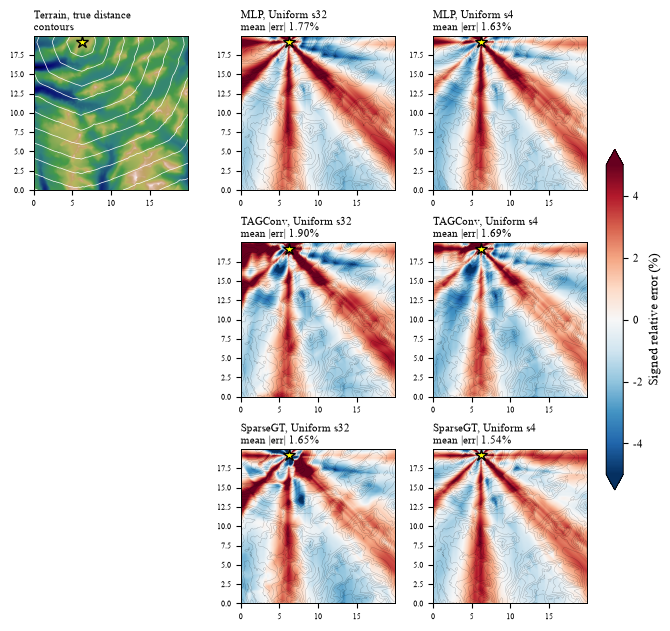

In [10]:
plot_heatmaps('uniform', strides=(32, 4), fname='e34_heatmap_uniform')